# BERT Reranker, example mixed-length workload: inf2.xlarge, native

[Alibaba-NLP/gte-multilingual-reranker-base](https://huggingface.co/Alibaba-NLP/gte-multilingual-reranker-base)
behind NVIDIA Triton Inference Server, benchmarked with an **example mixed-length workload**
rather than a fixed sequence length.

**Path**: PyTorch Native, `torch.compile(backend="neuron")` | **dtype**: full BF16 | **Triton model instances**: 2 (one per NeuronCore, each holding every length)

**GELU**: this notebook swaps the model's exact (erf) GELU for `nn.GELU(approximate="tanh")`.
On the PyTorch Native path exact GELU is lowered through FP32 and, on trn2 at seq=256 x 32, costs
about 36 ms of a 99 ms call; tanh GELU stays in BF16 and the call drops to 63 ms (+57%). On CPU in
FP32 the two GELUs give cosine 0.999995-0.999997 over 64 query/passage pairs at lengths 128-512, the
same top-1 for every query, and Spearman >= 0.997. The trace path is the same speed with either
GELU, so the trace notebooks keep the exact GELU.

**NKI kernels** (`nki_kernels/`, registered with `torch_neuronx.nki_op`, applied by `patch_model`):
- **Attention half** of every layer for lengths up to 512 -- `qkv_proj`, rotate-half RoPE, masked
  softmax attention, `o_proj`, residual add and `attn_ln` -- in one kernel (`attn_block_kernel.py`).
  Q/K weight columns are permuted on the host so RoPE needs no transposes, the 1/sqrt(d) scale is
  folded into the Q weights, and the key-padding mask and softmax denominator ride on an extra
  contraction row/column of the two attention matmuls.
- **Gated MLP** + residual + `mlp_ln` in one kernel with the weights resident on chip
  (`gated_mlp_kernel.py`).
- **LayerNorm** with a fused residual add using the Vector engine's `bn_stats`/`bn_aggr`
  (`res_ln_kernel.py`); PyTorch Native's own LayerNorm lowering does not use them. Used for the
  embedding LayerNorm and, at lengths 768/1024, after attention.
- At lengths 768 and 1024 the attention core runs nkilib's `attention_cte` (key-padding mask passed as
  sequence-packing bounds); below 768 the fused block above is used.
Shapes the kernels cannot take fall back to the stock modules.

## The example workload

An illustrative workload, in round numbers, shaped like a typical search reranker: mostly short
query+passage pairs sent in large batches. Five length buckets; the client groups each request's
sequences by length and sends one Triton call per bucket, up to 32 sequences per call.

| bucket | % Triton calls | mean sequences per call | % sequences (derived) | % compute (derived) |
|---:|---:|---:|---:|---:|
| 128 | 30 | 6 | 10.9 | 5.5 |
| 256 | 50 | 28 | 84.8 | 85.2 |
| 512 | 15 | 4 | 3.6 | 7.3 |
| 768 | 3 | 2 | 0.4 | 1.1 |
| 1024 | 2 | 2 | 0.2 | 1.0 |

Call sizes are drawn per bucket from a distribution with that mean. **To model your own traffic,
edit `EXAMPLE_MIX` in Step 5** and re-run; the bucket sets in Step 1 may then also need revisiting.

## What gets compiled

Sparse batch buckets per length, chosen from the call-size distribution. A call is routed to the
smallest compiled batch that fits it.

| length | PyTorch Native (24 graphs) | trace (12 graphs) |
|---:|---|---|
| 128 | 1, 4, 8, 16, 32 | 8, 32 |
| 256 | 8, 16, 24, 32 | 24, 28, 32 |
| 512 | 2, 4, 8, 16, 32 | 4, 8, 32 |
| 768 | 1, 2, 4, 8, 32 | 4, 32 |
| 1024 | 1, 2, 4, 8, 32 | 4, 32 |

**Why trace gets fewer graphs:** `torch_neuronx.trace` embeds the model weights in every compiled
graph (~0.75 GB each), so per-core device memory caps how many can be loaded. On inf2 (16 GB per
NeuronCore) loading failed at about 18 graphs. PyTorch Native keeps one copy of the weights shared
by all its graphs, so all 24 fit. The 12-graph trace set was chosen to minimise padded compute for
the example workload: padded compute is 1.15x the real compute, versus 1.13x for the 24-graph set.

## What gets measured

1. **Throughput vs latency**: a closed-loop sweep over client concurrency on gRPC. Each point gives
   sequences/s and call latency p50/p90/p99. Plotted and saved as JSON.
2. **Batching at seq=256**: sequences/s vs batch size with one call in flight, for the bucket that
   carries most of the compute in this example.


---
## Step 0: Environment

Every step that touches the Neuron device runs in a subprocess or container, never in this kernel:
a process that initialises the Neuron runtime keeps its cores until it exits.


In [1]:
import os, subprocess, sys, time, json, shutil, math, random

def sh(cmd, **kw):
    r = subprocess.run(cmd, shell=isinstance(cmd, str), capture_output=True, text=True, **kw)
    return r.stdout.strip(), r.stderr.strip(), r.returncode

PLATFORM, PATH, LNC = "inf2x", "native", "1"
DEV = "inf2"
TAG = "inf2x_native_nki"
QDELAY = 500
NUM_INSTANCES = 2
BETA4 = os.environ.get("NEURON_PTN_IMAGE", "public.ecr.aws/neuron/torch-neuronx:2.14.0-neuronx-py314-sdk2.33.0-ubuntu26.04")
TRACE_BASE = "public.ecr.aws/neuron/pytorch-inference-neuronx:2.9.0-neuronx-py312-sdk2.31.0-ubuntu24.04"
MODEL_ID = "Alibaba-NLP/gte-multilingual-reranker-base"
LENGTHS = [128, 256, 512, 768, 1024]
if PATH == "trace":
    # 12 graphs: trace embeds the weights in every graph (~0.75 GB each), so 24 do not fit in
    # per-core HBM. This set minimises padded compute for the traffic mix within that budget.
    BUCKETS = {128: [8, 32], 256: [24, 28, 32], 512: [4, 8, 32], 768: [4, 32], 1024: [4, 32]}
elif True:
    # finer batch buckets at the two busiest lengths: padded compute 1.13x -> ~1.06x (30 graphs)
    BUCKETS = {128: [1, 2, 4, 6, 8, 12, 16, 32], 256: [8, 12, 16, 20, 24, 28, 32], 512: [2, 4, 8, 16, 32],
                768: [1, 2, 4, 8, 32], 1024: [1, 2, 4, 8, 32]}
else:
    BUCKETS = {128: [1, 4, 8, 16, 32], 256: [8, 16, 24, 32], 512: [2, 4, 8, 16, 32],
                768: [1, 2, 4, 8, 32], 1024: [1, 2, 4, 8, 32]}
CONCURRENCY = [1, 2, 3, 4, 6, 8, 12, 16, 24, 32]
HOME = os.path.expanduser("~")
WORK = f"{HOME}/prodmix"
VAR = PATH + ("_nki" if True else "")
ART = f"{WORK}/artifacts_{VAR}_{DEV}_lnc{LNC}"   # compiled graphs / NEFF cache
REPO = f"{WORK}/repo_{VAR}_lnc{LNC}"
os.makedirs(ART, exist_ok=True)
NKI = True
if NKI:
    KDIR = f"{WORK}/nki_kernels"
    os.makedirs(KDIR, exist_ok=True)
    for _fn, _src in {'res_ln_kernel.py': '"""Fused residual add + LayerNorm (post-LN, with affine) for NewBERT on Neuron.\n\n    y = LayerNorm(x + r) * gamma + beta        x, r, y: [R, H] bf16, gamma/beta [128, H]\n\nPer 128-row tile:\n  * DMA engine:  s = x + r                (dma_compute, straight from HBM; no Vector add)\n  * Vector:      bn_stats / bn_aggr       (mean, var in fp32)\n  * Scalar:      rstd = rsqrt(var + eps)\n  * Vector:      u = (s - mean) * gamma   (one scalar_tensor_tensor)\n  * Scalar:      v = u * rstd\n  * DMA engine:  y = v + beta             (dma_compute, writes HBM)\n\n``has_residual=False`` skips the add (embedding LayerNorm). gamma/beta are passed\npre-broadcast to [128, H] once at load time. Rows are split across LNC programs, so\nR must be a multiple of 128 * LNC.\n\nPure NKI: no torch import, so the same body runs under nki.simulate.\n"""\n\nimport nki\nimport nki.isa as nisa\nimport nki.language as nl\n\nP = 128\n\n\n@nki.jit\ndef res_ln_kernel(x_hbm, r_hbm, g_hbm, b_hbm, eps=1e-12, has_residual=True):\n    R, H = x_hbm.shape\n    n_prog = nl.num_programs(0)\n    pid = nl.program_id(0)\n\n    assert R % (P * n_prog) == 0\n    fmax = nl.tile_size.bn_stats_fmax\n    n_chunk = (H + fmax - 1) // fmax\n    assert H % n_chunk == 0\n    csz = H // n_chunk\n\n    rows_per = R // n_prog\n    n_t = rows_per // P\n    r_base = pid * rows_per\n    dt = x_hbm.dtype\n    V2 = nisa.get_nc_version() == nisa.nc_version.gen2\n\n    y_hbm = nl.ndarray((R, H), dtype=dt, buffer=nl.shared_hbm)\n\n    g_sb = nl.ndarray((P, H), dtype=g_hbm.dtype, buffer=nl.sbuf)\n    b_sb = nl.ndarray((P, H), dtype=b_hbm.dtype, buffer=nl.sbuf)\n    nisa.dma_copy(dst=g_sb, src=g_hbm[0:P, 0:H])\n    nisa.dma_copy(dst=b_sb, src=b_hbm[0:P, 0:H])\n    if V2 and b_hbm.dtype != dt:  # gen2: dma_compute with mixed bf16/fp32 sources gives wrong results -> keep beta in the output dtype\n        b_lo = nl.ndarray((P, H), dtype=dt, buffer=nl.sbuf)\n        nisa.tensor_copy(dst=b_lo, src=b_sb)\n        b_sb = b_lo\n    eps_sb = nl.ndarray((P, 1), dtype=nl.float32, buffer=nl.sbuf)\n    nisa.memset(dst=eps_sb, value=eps)\n\n    for t in nl.affine_range(n_t):\n        r0 = r_base + t * P\n        s_sb = nl.ndarray((P, H), dtype=dt, buffer=nl.sbuf)\n        if has_residual:\n            nisa.dma_compute(dst=s_sb, srcs=[x_hbm[nl.ds(r0, P), 0:H], r_hbm[nl.ds(r0, P), 0:H]],\n                             reduce_op=nl.add)\n        else:\n            nisa.dma_copy(dst=s_sb, src=x_hbm[nl.ds(r0, P), 0:H])\n\n        stats = nl.ndarray((P, 6 * n_chunk), dtype=nl.float32, buffer=nl.sbuf)\n        for c in range(n_chunk):\n            nisa.bn_stats(dst=stats[0:P, c * 6:(c + 1) * 6], data=s_sb[0:P, c * csz:(c + 1) * csz])\n        mv = nl.ndarray((P, 2), dtype=nl.float32, buffer=nl.sbuf)\n        nisa.bn_aggr(dst=mv, data=stats)\n\n        rstd = nl.ndarray((P, 1), dtype=nl.float32, buffer=nl.sbuf)\n        nisa.activation(dst=rstd, op=nl.rsqrt, data=mv[0:P, 1:2], bias=eps_sb)\n\n        u_sb = nl.ndarray((P, H), dtype=dt, buffer=nl.sbuf)\n        nisa.scalar_tensor_tensor(dst=u_sb, data=s_sb, op0=nl.subtract, operand0=mv[0:P, 0:1],\n                                  op1=nl.multiply, operand1=g_sb)\n        v_sb = nl.ndarray((P, H), dtype=dt, buffer=nl.sbuf)\n        nisa.activation(dst=v_sb, op=nl.copy, data=u_sb, scale=rstd)\n        nisa.dma_compute(dst=y_hbm[nl.ds(r0, P), 0:H], srcs=[v_sb, b_sb], reduce_op=nl.add)\n\n    return y_hbm\n', 'gated_mlp_kernel.py': '"""Fused NewBERT gated MLP + residual + post-LayerNorm (replaces NewGatedMLP + mlp_ln).\n\n    h   = x @ Wup^T,  gt = x @ Wgate^T                 (up_gate_proj, no bias; split [up | gate])\n    m   = (gelu_tanh(gt) * h) @ Wd^T + bd              (down_proj)\n    y   = LayerNorm(x + m) * gamma + beta              (mlp_ln, residual = MLP input)\n\nShapes: x [R, K] bf16 (K = hidden, 768), wupT / wgT [K, I] bf16 (I = 3072), wdT [I, K] bf16,\nbd / gamma / beta pre-broadcast to [128, K] (fp32 or bf16). Returns y [R, K] bf16.\n\nLayout: all weights stay resident in SBUF (K-tiles x I for up/gate, I-tiles x K for down; ~110 KiB\nper partition at K=768, I=3072). Rows are processed in blocks of up to 512 (the matmul moving free\nsize). Per block:\n  * x rows are loaded once (row layout, kept for the residual) and transposed to x^T (K on\n    partitions) by DMA transpose.\n  * up/gate for each 128-wide I tile land in PSUM [128 (I), rows]; gelu_tanh on Scalar, multiply\n    on Vector -> g [I tile, rows] bf16, already in the layout the down-projection needs.\n  * down: per 128-row subtile, PSUM [128 rows, K] accumulated over the I tiles.\n  * epilogue: s = psum + x + bd (fp32), bn_stats/bn_aggr, y = (s - mean) * gamma * rstd + beta.\nR must be a multiple of 128 * LNC; rows are split across LNC programs. Inference only.\n"""\n\nimport nki\nimport nki.isa as nisa\nimport nki.language as nl\n\nP = 128\nFMAX = 512\n\n\ndef _cdiv(a, b):\n    return (a + b - 1) // b\n\n\n@nki.jit\ndef gated_mlp_ln_kernel(x_hbm, wupT_hbm, wgT_hbm, wdT_hbm, bd_hbm, g_hbm, b_hbm, eps=1e-12):\n    R, K = x_hbm.shape\n    K1, I = wupT_hbm.shape\n    assert K1 == K\n    assert K % P == 0\n    assert I % P == 0\n    n_prog = nl.num_programs(0)\n    pid = nl.program_id(0)\n    assert R % (P * n_prog) == 0\n    rows_per = R // n_prog\n    r_base = pid * rows_per\n    n_k = K // P\n    n_i = I // P\n    n_ko = _cdiv(K, FMAX)\n    n_blk = _cdiv(rows_per, FMAX)\n    fmax = nl.tile_size.bn_stats_fmax\n    n_ch = _cdiv(K, fmax)\n    csz = K // n_ch\n    dt = x_hbm.dtype\n    V2 = nisa.get_nc_version() == nisa.nc_version.gen2      # Inf2 / Trn1: DMA transpose must read HBM\n\n    y_hbm = nl.ndarray((R, K), dtype=dt, buffer=nl.shared_hbm)\n\n    # ---- resident weights ----\n    wu = []\n    wg = []\n    for kt in range(n_k):\n        tu = nl.ndarray((P, I), dtype=wupT_hbm.dtype, buffer=nl.sbuf)\n        nisa.dma_copy(dst=tu, src=wupT_hbm[kt * P:(kt + 1) * P, 0:I])\n        wu.append(tu)\n        tg = nl.ndarray((P, I), dtype=wgT_hbm.dtype, buffer=nl.sbuf)\n        nisa.dma_copy(dst=tg, src=wgT_hbm[kt * P:(kt + 1) * P, 0:I])\n        wg.append(tg)\n    wd = []\n    for it in range(n_i):\n        td = nl.ndarray((P, K), dtype=wdT_hbm.dtype, buffer=nl.sbuf)\n        nisa.dma_copy(dst=td, src=wdT_hbm[it * P:(it + 1) * P, 0:K])\n        wd.append(td)\n    bd_sb = nl.ndarray((P, K), dtype=bd_hbm.dtype, buffer=nl.sbuf)\n    nisa.dma_copy(dst=bd_sb, src=bd_hbm[0:P, 0:K])\n    ga_sb = nl.ndarray((P, K), dtype=g_hbm.dtype, buffer=nl.sbuf)\n    nisa.dma_copy(dst=ga_sb, src=g_hbm[0:P, 0:K])\n    be_sb = nl.ndarray((P, K), dtype=b_hbm.dtype, buffer=nl.sbuf)\n    nisa.dma_copy(dst=be_sb, src=b_hbm[0:P, 0:K])\n    if V2 and b_hbm.dtype != dt:  # gen2: dma_compute with mixed bf16/fp32 sources gives wrong results -> keep beta in the output dtype\n        be_lo = nl.ndarray((P, K), dtype=dt, buffer=nl.sbuf)\n        nisa.tensor_copy(dst=be_lo, src=be_sb)\n        be_sb = be_lo\n    eps_sb = nl.ndarray((P, 1), dtype=nl.float32, buffer=nl.sbuf)\n    nisa.memset(dst=eps_sb, value=eps)\n\n    for blk in range(n_blk):\n        q0 = blk * FMAX\n        rw = min(FMAX, rows_per - q0)\n        n_rs = rw // P\n        rb = r_base + q0\n\n        # ---- x rows (+bd folded in later) and x^T ----\n        xr = []\n        xt = []\n        for kt in range(n_k):\n            xt.append(nl.ndarray((P, FMAX), dtype=dt, buffer=nl.sbuf))\n        for rs in range(n_rs):\n            t = nl.ndarray((P, K), dtype=dt, buffer=nl.sbuf)\n            nisa.dma_copy(dst=t, src=x_hbm[nl.ds(rb + rs * P, P), 0:K])\n            xr.append(t)\n            for kt in range(n_k):\n                if V2:\n                    nisa.dma_transpose(dst=xt[kt][0:P, rs * P:(rs + 1) * P],\n                                       src=x_hbm[nl.ds(rb + rs * P, P), kt * P:(kt + 1) * P])\n                else:\n                    nisa.dma_transpose(dst=xt[kt][0:P, rs * P:(rs + 1) * P], src=t[0:P, kt * P:(kt + 1) * P])\n\n        # ---- up / gate -> g [I tile, rows] ----\n        gl = []\n        for it in range(n_i):\n            i0 = it * P\n            pu = nl.ndarray((P, FMAX), dtype=nl.float32, buffer=nl.psum)\n            for kt in nl.affine_range(n_k):\n                nisa.nc_matmul(dst=pu[0:P, 0:rw], stationary=wu[kt][0:P, i0:i0 + P], moving=xt[kt][0:P, 0:rw])\n            pg = nl.ndarray((P, FMAX), dtype=nl.float32, buffer=nl.psum)\n            for kt in nl.affine_range(n_k):\n                nisa.nc_matmul(dst=pg[0:P, 0:rw], stationary=wg[kt][0:P, i0:i0 + P], moving=xt[kt][0:P, 0:rw])\n            ge = nl.ndarray((P, FMAX), dtype=dt, buffer=nl.sbuf)\n            nisa.activation(dst=ge[0:P, 0:rw], op=nl.gelu_apprx_tanh, data=pg[0:P, 0:rw])\n            g = nl.ndarray((P, FMAX), dtype=dt, buffer=nl.sbuf)\n            nisa.tensor_tensor(dst=g[0:P, 0:rw], data1=pu[0:P, 0:rw], data2=ge[0:P, 0:rw], op=nl.multiply)\n            gl.append(g)\n\n        # ---- down + residual + LN, per 128-row subtile ----\n        for rs in range(n_rs):\n            s_sb = nl.ndarray((P, K), dtype=nl.float32, buffer=nl.sbuf)\n            xb = nl.ndarray((P, K), dtype=nl.float32, buffer=nl.sbuf)\n            nisa.tensor_tensor(dst=xb, data1=xr[rs], data2=bd_sb, op=nl.add,\n                               engine=nisa.engine.vector if V2 else nisa.engine.gpsimd)\n            for ko in range(n_ko):\n                k0 = ko * FMAX\n                nk = min(FMAX, K - k0)\n                pd = nl.ndarray((P, FMAX), dtype=nl.float32, buffer=nl.psum)\n                for it in nl.affine_range(n_i):\n                    nisa.nc_matmul(dst=pd[0:P, 0:nk], stationary=gl[it][0:P, rs * P:(rs + 1) * P],\n                                   moving=wd[it][0:P, k0:k0 + nk])\n                nisa.tensor_tensor(dst=s_sb[0:P, k0:k0 + nk], data1=pd[0:P, 0:nk], data2=xb[0:P, k0:k0 + nk],\n                                   op=nl.add)\n            stats = nl.ndarray((P, 6 * n_ch), dtype=nl.float32, buffer=nl.sbuf)\n            for c in range(n_ch):\n                nisa.bn_stats(dst=stats[0:P, c * 6:(c + 1) * 6], data=s_sb[0:P, c * csz:(c + 1) * csz])\n            mv = nl.ndarray((P, 2), dtype=nl.float32, buffer=nl.sbuf)\n            nisa.bn_aggr(dst=mv, data=stats)\n            rstd = nl.ndarray((P, 1), dtype=nl.float32, buffer=nl.sbuf)\n            nisa.activation(dst=rstd, op=nl.rsqrt, data=mv[0:P, 1:2], bias=eps_sb)\n            u_sb = nl.ndarray((P, K), dtype=dt, buffer=nl.sbuf)\n            nisa.scalar_tensor_tensor(dst=u_sb, data=s_sb, op0=nl.subtract, operand0=mv[0:P, 0:1],\n                                      op1=nl.multiply, operand1=ga_sb)\n            v_sb = nl.ndarray((P, K), dtype=dt, buffer=nl.sbuf)\n            nisa.activation(dst=v_sb, op=nl.copy, data=u_sb, scale=rstd)\n            nisa.dma_compute(dst=y_hbm[nl.ds(rb + rs * P, P), 0:K], srcs=[v_sb, be_sb], reduce_op=nl.add)\n\n    return y_hbm\n', 'attn_block_kernel.py': '"""Fused attention half of a NewBERT (gte) encoder layer, for PyTorch Native on Trainium2.\n\n    y = attn_ln(x + o_proj(softmax(rope(q) rope(k)^T / sqrt(d) + key_mask) v))\n\nReplaces qkv_proj + rotate-half RoPE + masked softmax attention + o_proj + residual + attn_ln.\n\nInputs (bf16 unless noted); weights are packed once on the host (attn_block_pack.pack):\n  x     [B*L, H]          layer input, token-major (head dim D = 64, NH = H / 64)\n  wqk   [H, 2*H]          Q and K projections, transposed, lane-permuted, Q pre-scaled by 1/sqrt(D)\n  bqk   [128, 2*H/128]    Q/K bias, same permutation, one column per 128-lane group (fp32)\n  wv    [H, H]            V projection transposed;   bv [128, H] broadcast (fp32)\n  wo    [H, H]            o_proj transposed;         bo [128, H] broadcast (fp32)\n  g, b  [128, H]          attn_ln weight / bias broadcast (fp32)\n  cs    [2, 128, L]       RoPE cos / sin per lane (fp32); lane l uses frequency l % 32\n  kb    [B, L]            additive key bias (0 valid, -30000 padded), right padding\nOutput y [B*L, H].\n\nDesign:\n  * Lane permutation: 128-lane group (j, par) holds lanes b*32+i = feature (4j+b)*D + par*32 + i of heads\n    4j..4j+3. par=0 holds the low halves, par=1 the high halves, so rotate-half RoPE is elementwise between\n    two lane groups (no transposes). Q and K share the order, so dot products are unchanged.\n  * The key mask and the softmax denominator ride on augmented contraction rows: Q^T gets a ones row and K^T\n    the key-bias row (one K=65 matmul gives S = QK^T + mask); V gets a ones column, so the P.V matmul also\n    returns sum(P).\n  * 2-4 short sequences share each projection pass (moving width up to 512).\n  * Sequences are split across the LNC programs. If the batch does not divide (e.g. B=1 at LNC=2) every\n    program computes K/V for all sequences and only its share of the query tiles (no cross-core reduction).\n  * The LayerNorm epilogue computes all statistics first and one rsqrt for the whole pass, so the Scalar\n    engine does not reload its activation table between rsqrt and exp on every tile.\nL must be a multiple of 128 and <= 512. Inference only.\n"""\n\nimport nki\nimport nki.isa as nisa\nimport nki.language as nl\n\nP = 128\nFMAX = 512\n\n\ndef _cdiv(a, b):\n    return (a + b - 1) // b\n\n\ndef _group(NH, L):\n    best = 1\n    for g in range(1, NH + 1):\n        if NH % g == 0 and g * L <= 1024:\n            best = g\n    return best\n\n\ndef _ln_out(s_sb, mean, rstd, ga, be, y_hbm, row0, P_, H, dt):\n    u_sb = nl.ndarray((P_, H), dtype=dt, buffer=nl.sbuf)\n    nisa.scalar_tensor_tensor(dst=u_sb, data=s_sb, op0=nl.subtract, operand0=mean,\n                              op1=nl.multiply, operand1=ga)\n    v_sb = nl.ndarray((P_, H), dtype=dt, buffer=nl.sbuf)\n    nisa.activation(dst=v_sb, op=nl.copy, data=u_sb, scale=rstd)\n    nisa.dma_compute(dst=y_hbm[nl.ds(row0, P_), 0:H], srcs=[v_sb, be], reduce_op=nl.add)\n\n\n@nki.jit\ndef attn_block_kernel(x_hbm, wqk_hbm, bqk_hbm, wv_hbm, bv_hbm, wo_hbm, bo_hbm, g_hbm, b_hbm, cs_hbm, kb_hbm,\n                      eps=1e-12):\n    R, H = x_hbm.shape\n    B, L = kb_hbm.shape\n    D = 64\n    NH = H // D\n    half = D // 2\n    quad = P // half                       # heads per 128-lane group (4)\n    NQ = NH // quad                        # lane groups per parity\n    assert NH * D == H\n    assert R == B * L\n    assert L % P == 0\n    assert L <= FMAX\n    assert H % P == 0\n    assert NH % quad == 0\n    n_prog = nl.num_programs(0)\n    pid = nl.program_id(0)\n    nt = L // P                            # token tiles per sequence\n    QS = 0                                 # query split across programs (batch not divisible)\n    if n_prog > 1 and B % n_prog != 0:\n        QS = 1\n    if QS == 1:\n        assert nt % n_prog == 0\n        Bp = B\n    else:\n        Bp = B // n_prog\n    n_k = H // P                           # contraction tiles over H\n    G = _group(NH, L)\n    NG = NH // G\n    n_ko = _cdiv(H, FMAX)\n    fmax = nl.tile_size.bn_stats_fmax\n    n_ch = _cdiv(H, fmax)\n    csz = H // n_ch\n    dt = x_hbm.dtype\n    V2 = nisa.get_nc_version() == nisa.nc_version.gen2      # Inf2 / Trn1 (NeuronCore-v2)\n    POOL = nisa.engine.vector if V2 else nisa.engine.gpsimd  # gen2 GpSimd cannot run these mixed-dtype ops\n\n    y_hbm = nl.ndarray((R, H), dtype=dt, buffer=nl.shared_hbm)\n\n    # ---------------- resident weights / constants ----------------\n    wqk = nl.ndarray((P, n_k, 2 * H), dtype=dt, buffer=nl.sbuf)\n    wv = nl.ndarray((P, n_k, H), dtype=dt, buffer=nl.sbuf)\n    wo = nl.ndarray((P, n_k, H), dtype=dt, buffer=nl.sbuf)\n    for kt in range(n_k):\n        nisa.dma_copy(dst=wqk[:, kt, :], src=wqk_hbm[kt * P:(kt + 1) * P, 0:2 * H])\n        nisa.dma_copy(dst=wv[:, kt, :], src=wv_hbm[kt * P:(kt + 1) * P, 0:H])\n        nisa.dma_copy(dst=wo[:, kt, :], src=wo_hbm[kt * P:(kt + 1) * P, 0:H])\n    bqk = nl.ndarray((P, 2 * H // P), dtype=nl.float32, buffer=nl.sbuf)\n    nisa.dma_copy(dst=bqk, src=bqk_hbm[0:P, 0:2 * H // P])\n    bv = nl.ndarray((P, H), dtype=bv_hbm.dtype, buffer=nl.sbuf)\n    nisa.dma_copy(dst=bv, src=bv_hbm[0:P, 0:H])\n    bo = nl.ndarray((P, H), dtype=bo_hbm.dtype, buffer=nl.sbuf)\n    nisa.dma_copy(dst=bo, src=bo_hbm[0:P, 0:H])\n    ga = nl.ndarray((P, H), dtype=g_hbm.dtype, buffer=nl.sbuf)\n    nisa.dma_copy(dst=ga, src=g_hbm[0:P, 0:H])\n    be = nl.ndarray((P, H), dtype=b_hbm.dtype, buffer=nl.sbuf)\n    nisa.dma_copy(dst=be, src=b_hbm[0:P, 0:H])\n    if V2 and b_hbm.dtype != dt:  # gen2: dma_compute with mixed bf16/fp32 sources gives wrong results -> keep beta in the output dtype\n        be_lo = nl.ndarray((P, H), dtype=dt, buffer=nl.sbuf)\n        nisa.tensor_copy(dst=be_lo, src=be)\n        be = be_lo\n    cos_t = nl.ndarray((P, L), dtype=nl.float32, buffer=nl.sbuf)\n    sin_t = nl.ndarray((P, L), dtype=nl.float32, buffer=nl.sbuf)\n    nisa.dma_copy(dst=cos_t, src=cs_hbm[0, 0:P, 0:L])\n    nisa.dma_copy(dst=sin_t, src=cs_hbm[1, 0:P, 0:L])\n    eps_sb = nl.ndarray((P, 1), dtype=nl.float32, buffer=nl.sbuf)\n    nisa.memset(dst=eps_sb, value=eps)\n\n    SP = 1                                 # sequences per projection pass\n    if QS == 0:\n        SP = FMAX // L\n        if SP > 4:\n            SP = 4\n        if Bp % SP != 0:\n            SP = 1\n    LW = L * SP                            # projection moving width\n    cosw = nl.ndarray((P, LW), dtype=dt, buffer=nl.sbuf)\n    sinw = nl.ndarray((P, LW), dtype=dt, buffer=nl.sbuf)\n    for sp in range(SP):\n        nisa.tensor_copy(dst=cosw[:, sp * L:(sp + 1) * L], src=cos_t)\n        nisa.tensor_copy(dst=sinw[:, sp * L:(sp + 1) * L], src=sin_t)\n\n    for bi in nl.affine_range(Bp // SP):\n        bseq = pid * Bp + bi * SP\n        if QS == 1:\n            bseq = bi\n        r0 = bseq * L\n        ntw = nt * SP                      # token tiles in this pass\n\n        # ---------------- x rows, x + bo, x^T ----------------\n        xr = nl.ndarray((P, ntw, H), dtype=dt, buffer=nl.sbuf)\n        xb = nl.ndarray((P, ntw, H), dtype=nl.float32, buffer=nl.sbuf)\n        xT = nl.ndarray((P, n_k, LW), dtype=dt, buffer=nl.sbuf)\n        for t in range(ntw):\n            nisa.dma_copy(dst=xr[:, t, :], src=x_hbm[nl.ds(r0 + t * P, P), 0:H])\n            nisa.tensor_tensor(dst=xb[:, t, :], data1=xr[:, t, :], data2=bo, op=nl.add, engine=POOL)\n            for kt in range(n_k):\n                if V2:\n                    nisa.dma_transpose(dst=xT[:, kt, t * P:(t + 1) * P],\n                                       src=x_hbm[nl.ds(r0 + t * P, P), kt * P:(kt + 1) * P])\n                else:\n                    nisa.dma_transpose(dst=xT[:, kt, t * P:(t + 1) * P], src=xr[:, t, kt * P:(kt + 1) * P])\n\n        # ---------------- Q/K projection + bias + RoPE -> qa / ka ----------------\n        qa = nl.ndarray((D + 1, NH, LW), dtype=dt, buffer=nl.sbuf)\n        ka = nl.ndarray((D + 1, NH, LW), dtype=dt, buffer=nl.sbuf)\n        nisa.memset(dst=qa[D:D + 1, :, :], value=1.0, engine=nisa.engine.gpsimd)\n        for sp in range(SP):\n            nisa.dma_copy(dst=ka[D:D + 1, :, sp * L:(sp + 1) * L],\n                          src=kb_hbm.ap(pattern=[[L, 1], [0, NH], [1, L]], offset=(bseq + sp) * L))\n        for qk in range(2):\n            dst_t = qa\n            if qk == 1:\n                dst_t = ka\n            for j in range(NQ):\n                pr = []\n                for par in range(2):\n                    gi = (qk * NQ + j) * 2 + par\n                    ps = nl.ndarray((P, LW), dtype=nl.float32, buffer=nl.psum)\n                    for kt in nl.affine_range(n_k):\n                        nisa.nc_matmul(dst=ps, stationary=wqk[:, kt, gi * P:(gi + 1) * P], moving=xT[:, kt, :])\n                    pt = nl.ndarray((P, LW), dtype=dt, buffer=nl.sbuf)\n                    if V2:     # gen2: Copy only takes an immediate bias -> Vector add of the bias column\n                        nisa.tensor_scalar(dst=pt, data=ps, op0=nl.add, operand0=bqk[:, gi:gi + 1])\n                    else:\n                        nisa.activation(dst=pt, op=nl.copy, data=ps, bias=bqk[:, gi:gi + 1])\n                    pr.append(pt)\n                lo = pr[0]\n                hi = pr[1]\n                a0 = nl.ndarray((P, LW), dtype=dt, buffer=nl.sbuf)\n                t0 = nl.ndarray((P, LW), dtype=dt, buffer=nl.sbuf)\n                a1 = nl.ndarray((P, LW), dtype=dt, buffer=nl.sbuf)\n                t1 = nl.ndarray((P, LW), dtype=dt, buffer=nl.sbuf)\n                nisa.tensor_tensor(dst=a0, data1=lo, data2=cosw, op=nl.multiply)\n                nisa.tensor_tensor(dst=t0, data1=hi, data2=sinw, op=nl.multiply, engine=nisa.engine.vector)\n                nisa.tensor_tensor(dst=a1, data1=hi, data2=cosw, op=nl.multiply)\n                nisa.tensor_tensor(dst=t1, data1=lo, data2=sinw, op=nl.multiply, engine=nisa.engine.vector)\n                r_lo = nl.ndarray((P, LW), dtype=dt, buffer=nl.sbuf)\n                r_hi = nl.ndarray((P, LW), dtype=dt, buffer=nl.sbuf)\n                nisa.tensor_tensor(dst=r_lo, data1=a0, data2=t0, op=nl.subtract)\n                nisa.tensor_tensor(dst=r_hi, data1=a1, data2=t1, op=nl.add)\n                # one copy per (head, half) 32-partition block. A single strided DMA spanning several\n                # partition blocks is exact in nki.simulate but only copies the first block on trn2.\n                for bq in range(quad):\n                    h = j * quad + bq\n                    rr = bq * half\n                    if V2:\n                        nisa.activation(dst=dst_t[0:half, h, :], op=nl.copy, data=r_lo[rr:rr + half, :])\n                    else:\n                        nisa.tensor_copy(dst=dst_t[0:half, h, :], src=r_lo[rr:rr + half, :],\n                                         engine=nisa.engine.scalar)\n                    nisa.tensor_copy(dst=dst_t[half:D, h, :], src=r_hi[rr:rr + half, :])\n\n        # ---------------- V projection (token-major) + bias -> va (ones column at D) ----------------\n        va = nl.ndarray((P, ntw, NH, D + 1), dtype=dt, buffer=nl.sbuf)\n        nisa.memset(dst=va[:, :, :, D:D + 1], value=1.0, engine=nisa.engine.gpsimd)\n        for t in range(ntw):\n            for ko in range(n_ko):\n                k0 = ko * FMAX\n                nk = min(FMAX, H - k0)\n                hv = nk // D\n                pv = nl.ndarray((P, FMAX), dtype=nl.float32, buffer=nl.psum)\n                for kt in nl.affine_range(n_k):\n                    nisa.nc_matmul(dst=pv[:, 0:nk], stationary=xT[:, kt, t * P:(t + 1) * P],\n                                   moving=wv[:, kt, k0:k0 + nk])\n                h0 = k0 // D\n                nisa.tensor_tensor(dst=va[:, t, h0:h0 + hv, 0:D], data1=pv[:, 0:nk], data2=bv[:, k0:k0 + nk],\n                                   op=nl.add)\n\n        # ---------------- attention + o_proj + residual + LN, per query tile ----------------\n        nq = ntw\n        if QS == 1:\n            nq = ntw // n_prog\n            qbase = pid * nq\n            xbq = nl.ndarray((P, nq, H), dtype=nl.float32, buffer=nl.sbuf)\n            for i in range(nq):\n                xq = nl.ndarray((P, H), dtype=dt, buffer=nl.sbuf)\n                nisa.dma_copy(dst=xq, src=x_hbm[nl.ds(r0 + (qbase + i) * P, P), 0:H])\n                nisa.tensor_tensor(dst=xbq[:, i, :], data1=xq, data2=bo, op=nl.add, engine=POOL)\n        s_all = nl.ndarray((P, nq, H), dtype=nl.float32, buffer=nl.sbuf)\n        mv_all = nl.ndarray((P, nq, 2), dtype=nl.float32, buffer=nl.sbuf)\n        for qi in range(nq):\n            sp = qi // nt\n            qt = qi % nt\n            c0 = sp * L                        # column offset of this sequence in qa/ka\n            t_off = sp * nt                    # token-tile offset of this sequence in va / xb\n            qcol = c0 + qt * P\n            xres = xb[:, t_off + qt, :]\n            if QS == 1:\n                qcol = (qbase + qi) * P\n                xres = xbq[:, qi, :]\n            o_sb = nl.ndarray((P, H), dtype=dt, buffer=nl.sbuf)\n            for gg in range(NG):\n                S = nl.ndarray((P, G, L), dtype=nl.float32, buffer=nl.psum)\n                for hl in range(G):\n                    h = gg * G + hl\n                    nisa.nc_matmul(dst=S[:, hl, :], stationary=qa[0:D + 1, h, nl.ds(qcol, P)],\n                                   moving=ka[0:D + 1, h, c0:c0 + L])\n                negmax = nl.ndarray((P, G), dtype=nl.float32, buffer=nl.sbuf)\n                nisa.tensor_reduce(dst=negmax, op=nl.maximum, data=S, axis=2, negate=True)\n                Pm = nl.ndarray((P, G, L), dtype=dt, buffer=nl.sbuf)\n                for hl in range(G):\n                    nisa.activation(dst=Pm[:, hl, :], op=nl.exp, data=S[:, hl, :], bias=negmax[:, hl:hl + 1])\n                PT = nl.ndarray((P, G, nt, P), dtype=dt, buffer=nl.sbuf)\n                if V2:\n                    PTp = nl.ndarray((P, G, nt, P), dtype=nl.float32, buffer=nl.psum)\n                    for hl in range(G):\n                        for kt in range(nt):\n                            nisa.nc_transpose(dst=PTp[:, hl, kt, :], data=Pm[:, hl, kt * P:(kt + 1) * P],\n                                              engine=nisa.engine.tensor)\n                    nisa.tensor_copy(dst=PT, src=PTp, engine=nisa.engine.vector)\n                else:\n                    nisa.dma_transpose(dst=PT.ap(pattern=[[G * L, P], [1, 1], [P, G * nt], [1, P]], offset=0),\n                                       src=Pm.ap(pattern=[[G * L, P], [1, 1], [P, G * nt], [1, P]], offset=0))\n                O = nl.ndarray((P, G, D + 1), dtype=nl.float32, buffer=nl.psum)\n                for hl in range(G):\n                    h = gg * G + hl\n                    for kt in nl.affine_range(nt):\n                        nisa.nc_matmul(dst=O[:, hl, :], stationary=PT[:, hl, kt, :], moving=va[:, t_off + kt, h, :])\n                rs = nl.ndarray((P, G, 1), dtype=nl.float32, buffer=nl.sbuf)\n                nisa.reciprocal(dst=rs, data=O[:, :, D:D + 1])\n                o3 = o_sb[:, gg * G * D:(gg + 1) * G * D].reshape((P, G, D))\n                nisa.tensor_tensor(dst=o3, data1=O[:, :, 0:D],\n                                   data2=rs.ap(pattern=[[G, P], [1, G], [0, D]], offset=0), op=nl.multiply)\n\n            # o^T for the output projection\n            oTp = nl.ndarray((P, n_k, P), dtype=nl.float32 if V2 else dt, buffer=nl.psum)\n            for kt in range(n_k):\n                nisa.nc_transpose(dst=oTp[:, kt, :], data=o_sb[:, kt * P:(kt + 1) * P], engine=nisa.engine.tensor)\n            oT = nl.ndarray((P, n_k, P), dtype=dt, buffer=nl.sbuf)\n            if V2:\n                nisa.activation(dst=oT, op=nl.copy, data=oTp)\n            else:\n                nisa.tensor_copy(dst=oT, src=oTp, engine=nisa.engine.scalar)\n\n            s_sb = s_all[:, qi, :]\n            for ko in range(n_ko):\n                k0 = ko * FMAX\n                nk = min(FMAX, H - k0)\n                po = nl.ndarray((P, FMAX), dtype=nl.float32, buffer=nl.psum)\n                for kt in nl.affine_range(n_k):\n                    nisa.nc_matmul(dst=po[:, 0:nk], stationary=oT[:, kt, :], moving=wo[:, kt, k0:k0 + nk])\n                nisa.tensor_tensor(dst=s_sb[:, k0:k0 + nk], data1=po[:, 0:nk], data2=xres[:, k0:k0 + nk],\n                                   op=nl.add)\n            stats = nl.ndarray((P, 6 * n_ch), dtype=nl.float32, buffer=nl.sbuf)\n            for c in range(n_ch):\n                nisa.bn_stats(dst=stats[:, c * 6:(c + 1) * 6], data=s_sb[:, c * csz:(c + 1) * csz])\n            nisa.bn_aggr(dst=mv_all[:, qi, :], data=stats)\n        rstd_all = nl.ndarray((P, nq, 1), dtype=nl.float32, buffer=nl.sbuf)\n        nisa.activation(dst=rstd_all, op=nl.rsqrt, data=mv_all[:, :, 1:2], bias=eps_sb)\n        for qi in range(nq):\n            yr = r0 + qi * P\n            if QS == 1:\n                yr = r0 + (qbase + qi) * P\n            _ln_out(s_all[:, qi, :], mv_all[:, qi, 0:1], rstd_all[:, qi, :], ga, be, y_hbm, yr, P, H, dt)\n\n    return y_hbm\n', 'attn_block_pack.py': '"""Host-side packing for attn_block_kernel (pure NumPy; used by the torch wrapper and the sim test)."""\nimport numpy as np\n\nP = 128\nD = 64\nHALF = 32\nQUAD = P // HALF\n\n\ndef lane_perm(NH):\n    """perm[g*128 + l] = feature index (within one projection) for lane group g = j*2 + par."""\n    NQ = NH // QUAD\n    perm = np.zeros(NH * D, np.int64)\n    for j in range(NQ):\n        for par in range(2):\n            g = j * 2 + par\n            for bq in range(QUAD):\n                h = j * QUAD + bq\n                for i in range(HALF):\n                    perm[g * P + bq * HALF + i] = h * D + par * HALF + i\n    return perm\n\n\ndef pack(wqkv, bqkv, wo, bo, g, b, cos, sin, H, scale, vb_fold=False):\n    """wqkv [3H, H], bqkv [3H] (qkv_proj, rows q|k|v), wo [H, H], bo [H] (o_proj), g/b [H] (attn_ln),\n    cos/sin [L, D] (RoPE table rows for positions 0..L-1). Returns dict of kernel inputs (fp32/np)."""\n    NH = H // D\n    perm = lane_perm(NH)\n    wq, wk, wv = wqkv[:H], wqkv[H:2 * H], wqkv[2 * H:]\n    bq, bk, bv = bqkv[:H], bqkv[H:2 * H], bqkv[2 * H:]\n    wq_p, bq_p = wq[perm] * scale, bq[perm] * scale\n    wk_p, bk_p = wk[perm], bk[perm]\n    wqk = np.concatenate([wq_p, wk_p], 0).T.copy()                          # [H, 2H]\n    bqk = np.concatenate([bq_p, bk_p]).reshape(-1, P).T.copy()              # [128, 2H/128]\n    lane_freq = np.arange(P) % HALF                                         # lane l -> freq index\n    cs = np.stack([cos[:, lane_freq].T, sin[:, lane_freq].T]).astype(np.float32)   # [2, 128, L]\n    bc = lambda v: np.tile(v.astype(np.float32), (P, 1))\n    if vb_fold:                     # softmax rows sum to 1: o_proj(PV + bv) = o_proj(PV) + Wo bv\n        bo = bo + wo @ bv\n    return dict(wqk=wqk, bqk=bqk.astype(np.float32), wv=wv.T.copy(), bv=bc(bv), wo=wo.T.copy(), bo=bc(bo),\n                g=bc(g), b=bc(b), cs=cs)\n', 'nki_kernels.py': '"""PyTorch Native wrappers for the NewBERT (gte) NKI kernels.\n\n    from nki_kernels import patch_model\n    model = AutoModelForSequenceClassification.from_pretrained(..., trust_remote_code=True,\n                                                               attn_implementation="eager")\n    # tanh-approximate GELU (see README), BF16, then patch, then move to the device and compile\n    model = model.to(torch.bfloat16)\n    patch_model(model)\n    model = model.to("neuron")\n    compiled = torch.compile(model, backend="neuron", dynamic=False)\n\nWhat patch_model replaces, per NewLayer:\n  * attention half (qkv_proj, RoPE, masked softmax attention, o_proj, residual, attn_ln) -> attn_block_kernel\n    for L in {128, 256, 384, 512}; other lengths keep the stock attention (with nkilib attention_cte for\n    L >= 768) followed by the residual+LayerNorm kernel.\n  * gated MLP + residual + mlp_ln -> gated_mlp_ln_kernel\n  * embedding LayerNorm -> res_ln_kernel (no residual)\nShapes the kernels cannot take (token count not a multiple of 128 x LNC, batch not divisible by LNC at\nL=128) fall back to the stock module; the shape is static per compiled graph, so the choice is made once.\n\nNEURON_LOGICAL_NC_CONFIG must be set before this module is imported (it fixes the kernel grid).\nInference only. Right-padded attention masks only.\n"""\nimport math\nimport os\nimport sys\nimport types\n\nimport torch\nfrom torch_neuronx import nki_op\n\nsys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))\nfrom attn_block_kernel import attn_block_kernel  # noqa: E402\nfrom attn_block_pack import pack as _pack_attn  # noqa: E402\nfrom gated_mlp_kernel import gated_mlp_ln_kernel  # noqa: E402\nfrom res_ln_kernel import res_ln_kernel  # noqa: E402\n\nLNC = int(os.environ.get("NEURON_LOGICAL_NC_CONFIG", "2"))\nATTN_LENGTHS = (128, 256, 384, 512)\nCTE_MIN_LEN = 768          # nkilib attention_cte beats the compiler\'s attention from here up\n\n\ndef _is_gen2():\n    """Inf2 / Trn1 (NeuronCore-v2; NKI target "trn1"). nkilib attention_cte\'s masked path (RangeSelect)\n    needs Trn2 or newer, so long sequences keep the compiler\'s attention there."""\n    try:\n        from torch_neuronx.utils import get_platform_target\n        return get_platform_target() == "trn1"\n    except Exception:\n        return False\n\n\nUSE_CTE = not _is_gen2()\n\n\n# ------------------------------------------------------------------------------- residual + LayerNorm\n@nki_op("gte_nki::res_ln", mutates_args={})\ndef res_ln(x: torch.Tensor, r: torch.Tensor, g: torch.Tensor, b: torch.Tensor, eps: float) -> torch.Tensor:\n    return res_ln_kernel[LNC](x, r, g, b, eps, True)\n\n\n@nki_op("gte_nki::ln", mutates_args={})\ndef ln(x: torch.Tensor, g: torch.Tensor, b: torch.Tensor, eps: float) -> torch.Tensor:\n    return res_ln_kernel[LNC](x, x, g, b, eps, False)\n\n\nclass NkiLN(torch.nn.Module):\n    """Drop-in for nn.LayerNorm(H) over the last dim, with an optional fused residual add."""\n\n    def __init__(self, ln_mod: torch.nn.LayerNorm):\n        super().__init__()\n        H = ln_mod.normalized_shape[0]\n        self.H, self.eps = H, float(ln_mod.eps)\n        self.register_buffer("g", ln_mod.weight.detach().float().reshape(1, H).expand(128, H).contiguous())\n        self.register_buffer("b", ln_mod.bias.detach().float().reshape(1, H).expand(128, H).contiguous())\n\n    def forward(self, x, residual=None):\n        shp = x.shape\n        x2 = x.reshape(-1, self.H)\n        if x2.shape[0] % (128 * LNC) != 0:\n            s = x if residual is None else x + residual\n            return torch.nn.functional.layer_norm(s, (self.H,), self.g[0].to(s.dtype), self.b[0].to(s.dtype),\n                                                  self.eps)\n        if residual is None:\n            y = ln(x2, self.g, self.b, self.eps)\n        else:\n            y = res_ln(x2, residual.reshape(-1, self.H), self.g, self.b, self.eps)\n        return y.reshape(shp)\n\n\n# ------------------------------------------------------------------------- gated MLP + residual + LN\n@nki_op("gte_nki::gated_mlp_ln", mutates_args={})\ndef gated_mlp_ln(x: torch.Tensor, wupT: torch.Tensor, wgT: torch.Tensor, wdT: torch.Tensor,\n                 bd: torch.Tensor, g: torch.Tensor, b: torch.Tensor, eps: float) -> torch.Tensor:\n    return gated_mlp_ln_kernel[LNC](x, wupT, wgT, wdT, bd, g, b, eps)\n\n\nclass NkiMlpLN(torch.nn.Module):\n    """Replaces NewGatedMLP + mlp_ln: y = LN(x + down(gelu_tanh(gate(x)) * up(x)))."""\n\n    def __init__(self, mlp, ln_mod):\n        super().__init__()\n        I = mlp.intermediate_size\n        w = mlp.up_gate_proj.weight.detach()           # [2I, K]: rows [0:I] up, [I:2I] gate\n        self.register_buffer("wupT", w[:I].t().contiguous())\n        self.register_buffer("wgT", w[I:].t().contiguous())\n        self.register_buffer("wdT", mlp.down_proj.weight.detach().t().contiguous())\n        K = self.wupT.shape[0]\n        bc = lambda v: v.detach().float().reshape(1, K).expand(128, K).contiguous()\n        self.register_buffer("bd", bc(mlp.down_proj.bias))\n        self.register_buffer("g", bc(ln_mod.weight))\n        self.register_buffer("b", bc(ln_mod.bias))\n        self.eps, self.K = float(ln_mod.eps), K\n        self._mlp, self._ln = [mlp], [ln_mod]          # stock fallback (not registered as children)\n\n    def forward(self, x):\n        x2 = x.reshape(-1, self.K)\n        if x2.shape[0] % (128 * LNC) != 0:\n            return self._ln[0](x + self._mlp[0](x))\n        return gated_mlp_ln(x2, self.wupT, self.wgT, self.wdT, self.bd, self.g, self.b, self.eps).reshape(x.shape)\n\n\n# ---------------------------------------------------------------- nkilib attention_cte for long sequences\n_cte = None\n\n\ndef _cte_attention(self, q, k, v, attention_bias, head_mask):\n    """q/k/v [B, L, nh, hd]; attention_bias [B, 1, 1, L] additive (0 valid, large negative for right padding)."""\n    global _cte\n    B, L, nh, hd = q.shape\n    if L < CTE_MIN_LEN or head_mask is not None or not USE_CTE:\n        return self._stock_attention(q, k, v, attention_bias, head_mask)\n    if _cte is None:\n        from torch_neuronx import wrap_nki\n        from nkilib.core.attention.attention_cte import attention_cte\n        _cte = wrap_nki(attention_cte)\n    scale = 1.0 / math.sqrt(hd)\n    qh = (q * scale).permute(0, 2, 1, 3).reshape(B * nh, L, hd)     # the bounds path requires scale=1.0\n    kh = k.permute(0, 2, 1, 3).reshape(B * nh, L, hd)\n    vh = v.permute(0, 2, 1, 3).reshape(B * nh, L, hd)\n    vl = (attention_bias.reshape(B, L) == 0).sum(-1).to(torch.float32)\n    bmax = vl.repeat_interleave(nh)[:, None, None].expand(B * nh, L, 1).contiguous()\n    o = _cte[LNC](qh, kh, vh, scale=1.0, causal_mask=False, tp_q=True, tp_k=True,\n                  bound_min=torch.zeros_like(bmax), bound_max=bmax)\n    return o.reshape(B, nh, L, hd).permute(0, 2, 1, 3).contiguous(), None\n\n\n# ------------------------------------------------------------------------------ fused attention half\n@nki_op("gte_nki::attn_block", mutates_args={})\ndef attn_block(x: torch.Tensor, wqk: torch.Tensor, bqk: torch.Tensor, wv: torch.Tensor, bv: torch.Tensor,\n               wo: torch.Tensor, bo: torch.Tensor, g: torch.Tensor, b: torch.Tensor, cs: torch.Tensor,\n               kb: torch.Tensor, eps: float) -> torch.Tensor:\n    return attn_block_kernel[LNC](x, wqk, bqk, wv, bv, wo, bo, g, b, cs, kb, eps)\n\n\nclass NkiAttnBlock(torch.nn.Module):\n    """attn_ln(x + attention(x)) for one NewLayer; RoPE tables packed once per supported length."""\n\n    def __init__(self, attn, ln_mod, rotary, lengths=ATTN_LENGTHS):\n        super().__init__()\n        H = attn.hidden_size\n        self.H, self.eps = H, float(ln_mod.eps)\n        sc = 1.0 / math.sqrt(attn.attention_head_size)\n        f = lambda t: t.detach().float().numpy()\n        cos, sin = rotary(torch.zeros(1, dtype=torch.float32), seq_len=max(lengths))\n        pk = _pack_attn(f(attn.qkv_proj.weight), f(attn.qkv_proj.bias), f(attn.o_proj.weight), f(attn.o_proj.bias),\n                        f(ln_mod.weight), f(ln_mod.bias), cos.float().numpy(), sin.float().numpy(), H, sc)\n        dt = attn.qkv_proj.weight.dtype\n        for k in ("wqk", "wv", "wo"):\n            self.register_buffer(k, torch.from_numpy(pk[k]).to(dt))\n        for k in ("bqk", "bv", "bo", "g", "b"):\n            self.register_buffer(k, torch.from_numpy(pk[k]).float())\n        for L in lengths:\n            self.register_buffer(f"cs{L}", torch.from_numpy(pk["cs"][:, :, :L].copy()).float())\n        self.lengths = set(lengths)\n        self._attn = [attn]\n        self.fallback_ln = NkiLN(ln_mod)\n\n    def forward(self, x, attention_bias, rope_embeds):\n        B, L, H = x.shape\n        query_split = (L // 128) % LNC == 0          # odd batches at LNC=2 split query tiles across cores\n        if L not in self.lengths or (B % LNC and not query_split):\n            a = self._attn[0](x, attention_bias, rope_embeds)[0]\n            return self.fallback_ln(a, x)\n        kb = attention_bias.reshape(B, L).float().clamp(min=-30000.0).to(x.dtype)\n        y = attn_block(x.reshape(B * L, H), self.wqk, self.bqk, self.wv, self.bv, self.wo, self.bo,\n                       self.g, self.b, getattr(self, f"cs{L}"), kb, self.eps)\n        return y.reshape(B, L, H)\n\n\ndef _layer_forward(self, hidden_states, attention_bias, rope_embeds=None, padding_inputs=None,\n                   attention_scale=None, subset_indices=None, head_mask=None,\n                   output_attentions=False, qkv_inputs=None):\n    hidden_states = self.attn_block(hidden_states, attention_bias, rope_embeds)\n    hidden_states = self.mlp_block(hidden_states)\n    return (hidden_states,)\n\n\ndef patch_model(model):\n    """Patch a NewModel-based model (BF16, eager attention) in place. Returns the number of layers patched."""\n    rot = None\n    for mod in model.modules():\n        if type(mod).__name__ == "NewEmbeddings":\n            rot = mod.rotary_emb\n            mod.LayerNorm = NkiLN(mod.LayerNorm)\n    assert rot is not None, "not a NewBERT (Alibaba-NLP new-impl) model"\n    n = 0\n    for mod in model.modules():\n        if type(mod).__name__ == "NewAttention":\n            mod._stock_attention = mod._attention\n            mod._attention = types.MethodType(_cte_attention, mod)\n    for mod in model.modules():\n        if type(mod).__name__ == "NewLayer":\n            assert "Gated" in type(mod.mlp).__name__, "expects the gated MLP variant"\n            mod.mlp_block = NkiMlpLN(mod.mlp, mod.mlp_ln)\n            mod.attn_block = NkiAttnBlock(mod.attention, mod.attn_ln, rot)\n            mod.forward = types.MethodType(_layer_forward, mod)\n            n += 1\n    return n\n'}.items():
        open(f"{KDIR}/{_fn}", "w").write(_src)

print(sh(f"NEURON_LOGICAL_NC_CONFIG={LNC} neuron-ls")[0])
print("graphs to compile:", sum(len(v) for v in BUCKETS.values()), BUCKETS)
print("host:", sh("nproc")[0], "vCPU,", sh("free -g | awk '/Mem:/{print $2}'")[0], "GB RAM,",
      sh("free -g | awk '/Swap/{print $2}'")[0], "GB swap")

instance-type: inf2.xlarge
instance-id: i-<redacted>
+--------+--------+----------+--------+--------------+----------+------+
| NEURON | NEURON |  NEURON  | NEURON |     PCI      |   CPU    | NUMA |
| DEVICE | CORES  | CORE IDS | MEMORY |     BDF      | AFFINITY | NODE |
+--------+--------+----------+--------+--------------+----------+------+
| 0      | 2      | 0-1      | 32 GB  | 0000:00:1f.0 | 0-3      | -1   |
+--------+--------+----------+--------+--------------+----------+------+
graphs to compile: 30 {128: [1, 2, 4, 6, 8, 12, 16, 32], 256: [8, 12, 16, 20, 24, 28, 32], 512: [2, 4, 8, 16, 32], 768: [1, 2, 4, 8, 32], 1024: [1, 2, 4, 8, 32]}
host: 4 vCPU, 15 GB RAM, 63 GB swap


---
## Step 1: Populate the NEFF cache for every (length, batch) graph

Runs inside the PyTorch Native (torch-neuronx) container on one core. Each graph is compiled with
`torch.compile(..., backend="neuron", dynamic=False)` into `TORCH_NEURONX_NEFF_CACHE_DIR`, which
every Triton instance mounts later. Accuracy is checked at every length on the largest batch.


In [2]:
pre = r"""
import os, sys, time, json
import numpy as np, torch, torch_neuronx
from transformers import AutoModelForSequenceClassification, AutoTokenizer
M = "Alibaba-NLP/gte-multilingual-reranker-base"
BUCKETS = {int(k): v for k, v in json.loads(os.environ["BUCKETS"]).items()}
import torch._dynamo as dyn
from torch._dynamo.utils import counters
# torch._dynamo caches at most cache_size_limit graphs per code object (default 8; it is the same
# setting as recompile_limit). Past that it silently runs the model EAGER, which (a) never puts a
# NEFF in the cache and (b) at seq=768, BS=32 returns wrong scores on this container. 24 shapes
# need a higher limit; the unique-graph count is checked below.
dyn.config.cache_size_limit = 64
dyn.config.accumulated_cache_size_limit = 512
dev = torch.device("neuron")
tok = AutoTokenizer.from_pretrained(M, trust_remote_code=True)
model = AutoModelForSequenceClassification.from_pretrained(
    M, trust_remote_code=True, attn_implementation="eager").eval()
# Exact (erf) GELU is lowered through FP32 on the PyTorch Native path and costs ~36 ms per
# seq=256 x 32 call on trn2; the tanh approximation stays in BF16 (see the notebook text).
for _mod in model.modules():
    for _cn, _c in _mod.named_children():
        if "GELU" in type(_c).__name__:
            setattr(_mod, _cn, torch.nn.GELU(approximate="tanh"))
model = model.to(torch.bfloat16)
if os.environ.get("NKI") == "1":
    sys.path.insert(0, "/work/nki_kernels")
    from nki_kernels import patch_model
    print("NKI layers patched:", patch_model(model), flush=True)
model = model.to(dev)
Q = "What are the benefits of renewable energy?"
P = ["Renewable energy sources like solar and wind power produce electricity without "
     "greenhouse gas emissions, reducing climate change impacts.",
     "The stock market experienced significant volatility in Q4, with tech stocks leading "
     "the decline amid rising interest rates.",
     "Solar panels have become 90% cheaper over the past decade, making renewable energy "
     "cost-competitive with fossil fuels.",
     "The history of ancient Rome spans over a thousand years, from its founding in 753 BC.",
     "Wind energy creates more jobs per megawatt than coal or natural gas power plants.",
     "Python is a popular programming language known for its readability."]
cpu = AutoModelForSequenceClassification.from_pretrained(
    M, trust_remote_code=True, attn_implementation="eager").eval()
acc = {}
for L in sorted(BUCKETS):
    for bs in BUCKETS[L]:
        cm = torch.compile(model, backend="neuron", dynamic=False)
        ids = torch.zeros((bs, L), dtype=torch.long, device=dev)
        msk = torch.ones((bs, L), dtype=torch.long, device=dev)
        t0 = time.time()
        with torch.no_grad():
            cm(ids, msk); torch_neuronx.synchronize()
        print(f"  L={L:>4} BS={bs:>2}: {time.time()-t0:5.0f}s", flush=True)
    bs = max(BUCKETS[L])
    cm = torch.compile(model, backend="neuron", dynamic=False)
    e = tok([Q] * len(P), P, return_tensors="pt", max_length=L, padding="max_length", truncation=True)
    with torch.no_grad():
        ref = cpu(e["input_ids"], e["attention_mask"]).logits[:, 0].float().numpy()
        pad = bs - len(P)
        ii = torch.cat([e["input_ids"], e["input_ids"][:1].repeat(pad, 1)]) if pad >= 0 else e["input_ids"][:bs]
        mm = torch.cat([e["attention_mask"], e["attention_mask"][:1].repeat(pad, 1)]) if pad >= 0 else e["attention_mask"][:bs]
        sc = cm(ii.to(dev), mm.to(dev)).logits[:min(bs, len(P)), 0].float().cpu().numpy()
    r = ref[:len(sc)]
    cos = float(np.dot(sc, r) / (np.linalg.norm(sc) * np.linalg.norm(r)))
    top = sorted(np.argsort(-sc)[:3].tolist())
    acc[L] = {"cosine": cos, "top3": top, "batch": bs}
    print(f"  L={L:>4} accuracy: cosine {cos:.6f} top-3 {top}", flush=True)
json.dump(acc, open("/cache/accuracy.json", "w"), indent=2)
n_shapes = sum(len(v) for v in BUCKETS.values())
ug = counters["stats"].get("unique_graphs", 0)
print(f"dynamo unique graphs: {ug} for {n_shapes} shapes", flush=True)
ok = ug >= n_shapes and all(v["cosine"] > 0.999 and v["top3"] == [0, 2, 4] for v in acc.values())
print("ACCURACY GATE", "PASSED" if ok else "FAILED")
n = sum(len(f) for _, _, f in os.walk("/cache"))
print(f"NEFF cache files: {n}")
"""
open(f"{WORK}/precompile_native.py", "w").write(pre)
open(f"{WORK}/precompile_native.sh", "w").write(
    "pip install -q 'transformers==4.53.3' 2>&1 | tail -1\npython3 /work/precompile_native.py\n")
cmd = ["sudo", "docker", "run", "--rm", "--entrypoint", "bash", "--device", "/dev/neuron0",
       "-e", f"NEURON_LOGICAL_NC_CONFIG={LNC}", "-e", f"NEURON_CC_FLAGS=--lnc={LNC}",
       "-e", "NEURON_RT_VISIBLE_CORES=0", "-e", "NEURON_RT_LOG_LEVEL=ERROR",
       "-e", "TORCH_NEURONX_NEFF_CACHE_DIR=/cache", "-e", f"NKI={int(NKI)}",
       "-e", "BUCKETS=" + json.dumps({str(k): v for k, v in BUCKETS.items()}),
       "-v", f"{WORK}:/work", "-v", f"{ART}:/cache",
       "-v", f"{HOME}/.cache/huggingface:/root/.cache/huggingface",
       BETA4, "/work/precompile_native.sh"]
t0 = time.time()
r = subprocess.run(cmd, capture_output=True, text=True, timeout=6 * 3600)
print("\n".join(l for l in r.stdout.splitlines() if l.startswith(("  L=", "ACCURACY", "NEFF", "dynamo", "NKI"))))
print(f"precompile took {(time.time()-t0)/60:.1f} min")
if "ACCURACY GATE PASSED" not in r.stdout:
    print(r.stderr[-3000:]); raise SystemExit("precompile/accuracy failed")

NKI layers patched: 12
  L= 128 BS= 1:    37s
  L= 128 BS= 2:    11s
  L= 128 BS= 4:    12s
  L= 128 BS= 6:    20s
  L= 128 BS= 8:    19s
  L= 128 BS=12:    25s
  L= 128 BS=16:    32s
  L= 128 BS=32:    56s
  L= 128 accuracy: cosine 0.999989 top-3 [0, 2, 4]
  L= 256 BS= 8:    35s
  L= 256 BS=12:    50s
  L= 256 BS=16:    63s
  L= 256 BS=20:    79s
  L= 256 BS=24:    93s
  L= 256 BS=28:   107s
  L= 256 BS=32:   120s
  L= 256 accuracy: cosine 0.999989 top-3 [0, 2, 4]
  L= 512 BS= 2:    24s
  L= 512 BS= 4:    42s
  L= 512 BS= 8:    77s
  L= 512 BS=16:   148s
  L= 512 BS=32:   294s
  L= 512 accuracy: cosine 0.999989 top-3 [0, 2, 4]
  L= 768 BS= 1:    48s
  L= 768 BS= 2:    65s
  L= 768 BS= 4:    58s
  L= 768 BS= 8:    70s
  L= 768 BS=32:    97s
  L= 768 accuracy: cosine 0.999998 top-3 [0, 2, 4]
  L=1024 BS= 1:    42s
  L=1024 BS= 2:    41s
  L=1024 BS= 4:    61s
  L=1024 BS= 8:    59s
  L=1024 BS=32:   111s
  L=1024 accuracy: cosine 0.999998 top-3 [0, 2, 4]
dynamo unique graphs: 30 for 30 

---
## Step 2: Triton model repository — one model for all lengths

A NeuronCore can be opened by only one process. Triton runs every model instance as its own
process, so separate models per length would put several processes on each core and all but one
would fail to start. Instead there is **one model, `reranker`, with one instance per core**, and
each instance loads all 24 (length, batch) graphs. The input sequence dimension is variable; the
backend reads the length from the call, routes to the smallest compiled batch that fits, pads,
runs and returns one score per sequence. Triton's dynamic batcher only merges requests of the
same shape, so batching still happens per length.


In [3]:
MODEL_PY = r"""
import json, os, time
import numpy as np
try:
    import triton_python_backend_utils as pb_utils
except ImportError:
    pb_utils = None
MODEL_ID = "Alibaba-NLP/gte-multilingual-reranker-base"


class TritonPythonModel:
    def initialize(self, args):
        cfg = json.loads(args["model_config"])
        p = lambda k, d: cfg.get("parameters", {}).get(k, {}).get("string_value", d)
        # One Triton model serves every length: a NeuronCore can be opened by one process only, so
        # there is one instance per core and each instance holds all (length, batch) graphs.
        self.buckets = {int(L): sorted(int(b) for b in bs.split(","))
                        for L, bs in json.loads(p("BUCKETS", "{}")).items()}
        n_inst = int(p("NUM_INSTANCES", "1"))
        idx = int(args.get("model_instance_name", "x_0").rsplit("_", 1)[-1] or 0)
        os.environ["NEURON_RT_VISIBLE_CORES"] = str(idx % n_inst)
        time.sleep(float(p("STAGGER_SEC", "2")) * idx)
        import torch, torch_neuronx
        import torch._dynamo as dyn
        from torch._dynamo.utils import counters
        dyn.config.cache_size_limit = 64          # default 8 silently falls back to eager
        from transformers import AutoModelForSequenceClassification
        self.torch, self.tnx = torch, torch_neuronx
        self.dev = torch.device("neuron")
        m = AutoModelForSequenceClassification.from_pretrained(
            MODEL_ID, trust_remote_code=True, attn_implementation="eager").eval()
        # tanh-approximate GELU: exact GELU goes through FP32 on the Native path (see notebook)
        for _mod in m.modules():
            for _cn, _c in _mod.named_children():
                if "GELU" in type(_c).__name__:
                    setattr(_mod, _cn, torch.nn.GELU(approximate="tanh"))
        m = m.to(torch.bfloat16)
        if p("NKI", "0") == "1":
            import sys
            sys.path.insert(0, "/work/nki_kernels")
            from nki_kernels import patch_model
            self._log(f"NKI layers patched: {patch_model(m)}")
        m = m.to(self.dev)
        self.models = {}
        t0 = time.time()
        for L, bss in sorted(self.buckets.items()):
            for bs in bss:
                cm = torch.compile(m, backend="neuron", dynamic=False)
                ids = torch.zeros((bs, L), dtype=torch.long, device=self.dev)
                msk = torch.ones((bs, L), dtype=torch.long, device=self.dev)
                with torch.no_grad():
                    for _ in range(2):
                        cm(ids, msk)
                    torch_neuronx.synchronize()
                self.models[(L, bs)] = cm
        ug = counters["stats"].get("unique_graphs", 0)
        if ug < len(self.models):
            raise RuntimeError(f"only {ug} graphs compiled for {len(self.models)} shapes: eager fallback")
        self._log(f"instance {idx} -> core {idx % n_inst} ready, {ug} compiled graphs "
                  f"in {time.time()-t0:.0f}s")

    def _log(self, m):
        (pb_utils.Logger.log_info if pb_utils else print)(f"[reranker] {m}")

    def _route(self, L, n):
        for b in self.buckets[L]:
            if b >= n:
                return b
        return self.buckets[L][-1]

    def execute(self, requests):
        torch = self.torch
        out = []
        for req in requests:
            ids_np = pb_utils.get_input_tensor_by_name(req, "input_ids").as_numpy()
            msk_np = pb_utils.get_input_tensor_by_name(req, "attention_mask").as_numpy()
            n, L = ids_np.shape
            if L not in self.buckets:
                raise ValueError(f"sequence length {L} is not one of {sorted(self.buckets)}")
            cap = self.buckets[L][-1]
            scores = np.empty((n, 1), dtype=np.float32)
            done = 0
            while done < n:
                take = min(n - done, cap)
                bs = self._route(L, take)
                ids = torch.as_tensor(ids_np[done:done + take], dtype=torch.long)
                msk = torch.as_tensor(msk_np[done:done + take], dtype=torch.long)
                if take < bs:
                    ids = torch.cat([ids, ids[:1].repeat(bs - take, 1)])
                    msk = torch.cat([msk, msk[:1].repeat(bs - take, 1)])
                with torch.no_grad():
                    lg = self.models[(L, bs)](ids.to(self.dev), msk.to(self.dev)).logits
                scores[done:done + take] = lg[:take, 0:1].float().cpu().numpy()
                done += take
            out.append(pb_utils.InferenceResponse(output_tensors=[pb_utils.Tensor("score", scores)]))
        return out
"""

if os.path.exists(REPO):
    sh(["sudo", "rm", "-rf", REPO])     # the container leaves root-owned __pycache__ behind
d = f"{REPO}/reranker"
os.makedirs(f"{d}/1", exist_ok=True)
open(f"{d}/1/model.py", "w").write(MODEL_PY)
all_bs = sorted({b for v in BUCKETS.values() for b in v})
bjson = json.dumps({str(k): ",".join(map(str, v)) for k, v in BUCKETS.items()}).replace('"', '\\"')
open(f"{d}/config.pbtxt", "w").write(f"""name: "reranker"
backend: "python"
max_batch_size: {max(all_bs)}
input [
  {{ name: "input_ids"      data_type: TYPE_INT64 dims: [ -1 ] }},
  {{ name: "attention_mask" data_type: TYPE_INT64 dims: [ -1 ] }}
]
output [ {{ name: "score" data_type: TYPE_FP32 dims: [ 1 ] }} ]
instance_group [ {{ kind: KIND_MODEL count: {NUM_INSTANCES} }} ]
# Triton only merges requests of identical shape, so dynamic batching stays per length.
dynamic_batching {{
  preferred_batch_size: [ {", ".join(map(str, all_bs))} ]
  max_queue_delay_microseconds: {QDELAY}
}}
parameters [
  {{ key: "BUCKETS"       value: {{ string_value: "{bjson}" }} }},
  {{ key: "NUM_INSTANCES" value: {{ string_value: "{NUM_INSTANCES}" }} }},
  {{ key: "ARTIFACTS"     value: {{ string_value: "/artifacts" }} }},
  {{ key: "STAGGER_SEC"   value: {{ string_value: "2" }} }},
  {{ key: "NKI"           value: {{ string_value: "{int(NKI)}" }} }}
]
""")
print(open(f"{REPO}/reranker/config.pbtxt").read())

name: "reranker"
backend: "python"
max_batch_size: 32
input [
  { name: "input_ids"      data_type: TYPE_INT64 dims: [ -1 ] },
  { name: "attention_mask" data_type: TYPE_INT64 dims: [ -1 ] }
]
output [ { name: "score" data_type: TYPE_FP32 dims: [ 1 ] } ]
instance_group [ { kind: KIND_MODEL count: 2 } ]
# Triton only merges requests of identical shape, so dynamic batching stays per length.
dynamic_batching {
  preferred_batch_size: [ 1, 2, 4, 6, 8, 12, 16, 20, 24, 28, 32 ]
  max_queue_delay_microseconds: 500
}
parameters [
  { key: "BUCKETS"       value: { string_value: "{\"128\": \"1,2,4,6,8,12,16,32\", \"256\": \"8,12,16,20,24,28,32\", \"512\": \"2,4,8,16,32\", \"768\": \"1,2,4,8,32\", \"1024\": \"1,2,4,8,32\"}" } },
  { key: "NUM_INSTANCES" value: { string_value: "2" } },
  { key: "ARTIFACTS"     value: { string_value: "/artifacts" } },
  { key: "STAGGER_SEC"   value: { string_value: "2" } },
  { key: "NKI"           value: { string_value: "1" } }
]



---
## Step 3: Build the Triton image and start the server

Triton r26.01 (python backend) is built from source on the base image for the chosen path. The
Native base image needs two fixes: an internal apt source that returns 401 is removed, and
`distro`, `build` and `virtualenv` are installed for Triton's build script. The image build is
skipped if it already exists.


In [4]:
BASE = TRACE_BASE if PATH == "trace" else BETA4
IMAGE = f"triton-prodmix-{PATH}:r26.01"
if not sh(["sudo", "docker", "images", "-q", IMAGE])[0]:
    py = "/opt/conda/bin/python3" if PATH == "trace" else "/usr/local/bin/python3"
    pylibdir = "/opt/conda/lib" if PATH == "trace" else "/usr/local/lib"
    df = f"""FROM {BASE}
ENV DEBIAN_FRONTEND=noninteractive
RUN grep -rl "artifacts.beta.neuron" /etc/apt/sources.list /etc/apt/sources.list.d/ 2>/dev/null | xargs -r rm -f \\
 && apt-get update && apt-get install -y --no-install-recommends \\
      git build-essential pkg-config rapidjson-dev libb64-dev libre2-dev libssl-dev \\
      libcurl4-openssl-dev libnuma-dev libarchive-dev zlib1g-dev libboost-dev \\
      autoconf automake libtool patchelf && rm -rf /var/lib/apt/lists/*
RUN {py} -m pip install --no-cache-dir "cmake==3.31.10" wheel setuptools distro requests build virtualenv \\
 && {py} -m pip install --no-cache-dir "transformers==4.53.3"
RUN PY={py} \\
 && PYINC=$($PY -c 'import sysconfig;print(sysconfig.get_paths()["include"])') \\
 && PYLIB=$($PY -c 'import sysconfig,os;print(os.path.join(sysconfig.get_config_var("LIBDIR"),"libpython"+sysconfig.get_config_var("LDVERSION")+".so"))') \\
 && test -f "$PYLIB" && echo "linking python backend against $PYLIB" \\
 && git clone --depth=1 --branch=r26.01 https://github.com/triton-inference-server/server.git /server \\
 && cd /server && PATH=$(dirname $PY):$PATH Python3_EXECUTABLE=$PY Python3_INCLUDE_DIR=$PYINC Python3_LIBRARY=$PYLIB \\
    ./build.py -v --no-container-build --build-dir=/server/build --backend=python \\
      --enable-logging --enable-stats --endpoint=http --endpoint=grpc \\
 && cp -r /server/build/opt/* /opt/ && cd / && rm -rf /server
ENV PATH=/opt/tritonserver/bin:$PATH
ENV LD_LIBRARY_PATH={pylibdir}:$LD_LIBRARY_PATH
# Build-time check only: import numpy (and torch with device autoload off -- there is no
# /dev/neuron at build time, and torch_neuronx refuses to load without one).
RUN ldd /opt/tritonserver/backends/python/triton_python_backend_stub | grep libpython \\
 && TORCH_DEVICE_BACKEND_AUTOLOAD=0 {py} -c "import numpy, torch; print('stub python has numpy', numpy.__version__, 'torch', torch.__version__)"
ENTRYPOINT []
"""
    open(f"{WORK}/Dockerfile.{PATH}", "w").write(df)
    t0 = time.time()
    r = subprocess.run(["sudo", "docker", "build", "-t", IMAGE, "-f", f"{WORK}/Dockerfile.{PATH}", WORK],
                       capture_output=True, text=True, timeout=7200)
    print(f"build {'OK' if r.returncode == 0 else 'FAILED'} in {(time.time()-t0)/60:.1f} min")
    if r.returncode:
        print(r.stdout[-3000:]); print(r.stderr[-3000:]); raise SystemExit("docker build failed")
else:
    print("image exists:", IMAGE)

import requests
CONTAINER = "triton-prodmix"
sh(["sudo", "docker", "rm", "-f", CONTAINER])
cmd = ["sudo", "docker", "run", "-d", "--name", CONTAINER, "--device", "/dev/neuron0",
       "--shm-size=16g", "-p", "8000:8000", "-p", "8001:8001", "-p", "8002:8002",
       "-e", f"NEURON_LOGICAL_NC_CONFIG={LNC}", "-e", "NEURON_RT_LOG_LEVEL=ERROR",
       "-e", "TOKENIZERS_PARALLELISM=false", "-e", "PYTHONDONTWRITEBYTECODE=1",
       "-v", f"{REPO}:/models", "-v", f"{ART}:/artifacts", "-v", f"{WORK}:/work",
       "-v", f"{HOME}/.cache/huggingface:/root/.cache/huggingface"]
if PATH == "native":
    cmd += ["-e", f"NEURON_CC_FLAGS=--lnc={LNC}", "-e", "TORCH_NEURONX_NEFF_CACHE_DIR=/artifacts"]
cmd += [IMAGE, "tritonserver", "--model-repository=/models", "--exit-on-error=true"]
print(sh(cmd)[0][:12])
t0 = time.time(); ready = False
while time.time() - t0 < 5400:
    if "Exited" in sh(f"sudo docker ps -a --filter name={CONTAINER} --format '{{{{.Status}}}}'")[0]:
        print(sh(f"sudo docker logs {CONTAINER} 2>&1 | grep -E '^E|Error|rror:' | head -20")[0])
        raise SystemExit("tritonserver exited during model load")
    try:
        if requests.get("http://localhost:8000/v2/models/reranker/ready", timeout=2).status_code == 200:
            ready = True; break
    except Exception:
        pass
    time.sleep(10)
if not ready:
    print(sh(f"sudo docker logs --tail 80 {CONTAINER} 2>&1")[0]); raise SystemExit("server not ready")
print(f"SERVER READY in {(time.time()-t0)/60:.1f} min;",
      sh(f"sudo docker logs {CONTAINER} 2>&1 | grep -c ' ready, '")[0], "model instances loaded")
print(sh(f"sudo docker logs {CONTAINER} 2>&1 | grep ' ready, ' | head -8")[0])



build OK in 30.1 min


2a43968aa32a


SERVER READY in 5.4 min; 2 model instances loaded
I1020 22:16:07.050366 1 model.py:63] "[reranker] instance 0 -> core 0 ready, 30 compiled graphs in 292s"
I1020 22:16:07.062920 1 model.py:63] "[reranker] instance 1 -> core 1 ready, 30 compiled graphs in 292s"


---
## Step 4: Accuracy through the server

Six labelled passages are scored through every length model over gRPC and compared with a CPU FP32
reference. A call of each size class is also checked for **padding isolation**: the score of a
sequence must not change when the other sequences in its call change.


In [5]:
import numpy as np
import tritonclient.grpc as grpcclient
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained(MODEL_ID, trust_remote_code=True)
GC = grpcclient.InferenceServerClient(url="localhost:8001")

def infer(L, ids, msk, client=None):
    c = client or GC
    a = grpcclient.InferInput("input_ids", ids.shape, "INT64"); a.set_data_from_numpy(ids)
    b = grpcclient.InferInput("attention_mask", msk.shape, "INT64"); b.set_data_from_numpy(msk)
    return c.infer("reranker", [a, b]).as_numpy("score")[:, 0]

Q = "What are the benefits of renewable energy?"
P = ["Renewable energy sources like solar and wind power produce electricity without "
     "greenhouse gas emissions, reducing climate change impacts.",
     "The stock market experienced significant volatility in Q4, with tech stocks leading "
     "the decline amid rising interest rates.",
     "Solar panels have become 90% cheaper over the past decade, making renewable energy "
     "cost-competitive with fossil fuels.",
     "The history of ancient Rome spans over a thousand years, from its founding in 753 BC.",
     "Wind energy creates more jobs per megawatt than coal or natural gas power plants.",
     "Python is a popular programming language known for its readability."]
acc = json.load(open(f"{ART}/accuracy.json"))
print("compile-time accuracy per length:",
      {L: round(v["cosine"], 6) for L, v in sorted(acc.items(), key=lambda kv: int(kv[0]))})
FILL = "Completely unrelated text about ancient Roman architecture and history."
ok = True
for L in LENGTHS:
    e = tok([Q] * 6, P, max_length=L, padding="max_length", truncation=True, return_tensors="np")
    s = infer(L, e["input_ids"].astype(np.int64), e["attention_mask"].astype(np.int64))
    top = sorted(np.argsort(-s)[:3].tolist())
    # padding isolation at a batch that pads up to a larger compiled graph
    n = 3
    e1 = tok([Q] * n, [P[0]] * n, max_length=L, padding="max_length", truncation=True, return_tensors="np")
    e2 = tok([Q] * n, [P[0]] + [FILL] * (n - 1), max_length=L, padding="max_length", truncation=True, return_tensors="np")
    a1 = infer(L, e1["input_ids"].astype(np.int64), e1["attention_mask"].astype(np.int64))[0]
    a2 = infer(L, e2["input_ids"].astype(np.int64), e2["attention_mask"].astype(np.int64))[0]
    iso = (a1 == a2)
    ok &= (top == [0, 2, 4]) and iso
    print(f"  L={L:>4}: top-3 {top}  padding isolation {'bit-exact' if iso else f'DIFFERS {a1} vs {a2}'}")
assert ok, "server-side accuracy check failed"
print("SERVER ACCURACY PASSED")

compile-time accuracy per length: {'128': 0.999989, '256': 0.999989, '512': 0.999989, '768': 0.999998, '1024': 0.999998}


  L= 128: top-3 [0, 2, 4]  padding isolation bit-exact
  L= 256: top-3 [0, 2, 4]  padding isolation bit-exact
  L= 512: top-3 [0, 2, 4]  padding isolation bit-exact


  L= 768: top-3 [0, 2, 4]  padding isolation bit-exact
  L=1024: top-3 [0, 2, 4]  padding isolation bit-exact
SERVER ACCURACY PASSED


---
## Step 5: Throughput vs latency, example workload replay

Closed loop over gRPC: `C` client threads each send replayed calls back to back for 20 s, after a
5 s warmup. Each thread owns its own gRPC client (Triton clients are bound to the thread that first
uses them). Calls are pre-tokenised so the client measures the server, not the tokenizer.

Reported per point: **sequences/s** (inferences/s), calls/s, call latency p50/p90/p99, and the
replayed bucket mix so it can be checked against the target.


In [6]:
import threading
from queue import Queue
# Example workload: length bucket -> (% of Triton calls, mean sequences per call). Edit to model
# your own traffic.
EXAMPLE_MIX = {128: (30, 6), 256: (50, 28), 512: (15, 4), 768: (3, 2), 1024: (2, 2)}
CALL_PCT = {L: v[0] for L, v in EXAMPLE_MIX.items()}
MEAN_B = {L: v[1] for L, v in EXAMPLE_MIX.items()}
_tot = sum(CALL_PCT[L] * MEAN_B[L] for L in CALL_PCT)
TARGET_SEQ_PCT = {L: CALL_PCT[L] * MEAN_B[L] / _tot * 100 for L in CALL_PCT}
CAP = 32

def trunc_mean(lam):
    p = [math.exp(-lam) * lam ** k / math.factorial(k) for k in range(CAP)]
    return sum((k + 1) * pk for k, pk in enumerate(p)) / sum(p)
LAM = {}
for L, m in MEAN_B.items():
    lo, hi = 0.0, 60.0
    for _ in range(60):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if trunc_mean(mid) < m else (lo, mid)
    LAM[L] = lo

def draw_size(rng, L):
    lam = LAM[L]
    while True:
        k, p, e = 0, 1.0, math.exp(-lam)
        while True:
            p *= rng.random()
            if p < e:
                break
            k += 1
        if k < CAP:
            return k + 1

# Pre-tokenised pool of realistic pairs per length (query + passage padded to the bucket length).
rng0 = random.Random(0)
words = ("energy solar wind market price policy grid storage battery carbon emission climate "
         "power plant cost demand supply research data model system network capacity").split()
POOL = {}
for L in LENGTHS:
    n_words = {128: 60, 256: 150, 512: 330, 768: 520, 1024: 700}[L]
    docs = [" ".join(rng0.choice(words) for _ in range(n_words)) for _ in range(64)]
    e = tok([Q] * 64, docs, max_length=L, padding="max_length", truncation=True, return_tensors="np")
    POOL[L] = (e["input_ids"].astype(np.int64), e["attention_mask"].astype(np.int64))

Ls, Ws = list(CALL_PCT), [CALL_PCT[L] for L in CALL_PCT]

def make_call(rng):
    L = rng.choices(Ls, Ws)[0]
    n = draw_size(rng, L)
    idx = [rng.randrange(64) for _ in range(n)]
    return L, POOL[L][0][idx], POOL[L][1][idx]

def run_point(C, dur=20.0, warm=5.0):
    lat, nseq, ncall, mix, errs = [], [0] * C, [0] * C, {L: 0 for L in LENGTHS}, []
    lock = threading.Lock()
    t_start = time.time() + warm
    t_end = t_start + dur
    def worker(k):
        rng = random.Random(1000 + k)
        cl = grpcclient.InferenceServerClient(url="localhost:8001")
        try:
            while True:
                L, ids, msk = make_call(rng)
                s = time.time()
                if s >= t_end:
                    break
                infer(L, ids, msk, cl)
                e = time.time()
                if s >= t_start:
                    with lock:
                        lat.append((e - s) * 1000); mix[L] += ids.shape[0]
                    nseq[k] += ids.shape[0]; ncall[k] += 1
        except Exception as ex:
            errs.append(f"{k}: {type(ex).__name__}: {ex}")
    ts = [threading.Thread(target=worker, args=(k,)) for k in range(C)]
    [t.start() for t in ts]; [t.join() for t in ts]
    if errs or min(ncall) == 0:
        raise RuntimeError(f"C={C}: {sum(n == 0 for n in ncall)} idle workers; {errs[:3]}")
    tot = sum(nseq)
    return {"concurrency": C, "seq_per_s": tot / dur, "calls_per_s": sum(ncall) / dur,
            "p50_ms": float(np.percentile(lat, 50)), "p90_ms": float(np.percentile(lat, 90)),
            "p99_ms": float(np.percentile(lat, 99)), "calls": sum(ncall), "sequences": tot,
            "seq_mix_pct": {L: round(mix[L] / tot * 100, 2) for L in LENGTHS},
            "mean_seq_per_call": tot / sum(ncall)}

# Warm every (length, batch) graph on every instance through the server, so the first sweep point
# does not pay first-call costs. NUM_INSTANCES concurrent calls per shape spread across instances.
def _warm_shape(L, bs):
    cl = grpcclient.InferenceServerClient(url="localhost:8001")
    infer(L, POOL[L][0][:bs], POOL[L][1][:bs], cl)
t0 = time.time()
for L in LENGTHS:
    for bs in BUCKETS[L]:
        for _ in range(2):
            ts = [threading.Thread(target=_warm_shape, args=(L, bs)) for _ in range(NUM_INSTANCES)]
            [t.start() for t in ts]; [t.join() for t in ts]
print(f"server-side warmup of {sum(len(v) for v in BUCKETS.values())} shapes x {NUM_INSTANCES} "
      f"instances took {time.time()-t0:.0f}s")

# Then run the replay itself, untimed, until the C=1 tail settles: the shape-by-shape warmup leaves
# some first-call cost on paths (e.g. a padded call whose source rows differ) that only real traffic
# exercises. Each pass is 10 s; stop once C=1 p99 is within 2x of its p50.
for i in range(6):
    w1 = run_point(min(8, max(CONCURRENCY)), dur=10.0, warm=0.0)
    w2 = run_point(1, dur=10.0, warm=0.0)
    print(f"  replay warmup pass {i}: C=1 p50 {w2['p50_ms']:.1f} ms, p99 {w2['p99_ms']:.1f} ms")
    if w2["p99_ms"] < 2 * w2["p50_ms"]:
        break

CURVE = []
print(f"{'C':>4} {'seq/s':>9} {'calls/s':>8} {'p50':>8} {'p90':>8} {'p99':>8}  seq mix 128/256/512/768/1024")
for C in CONCURRENCY:
    r = run_point(C); CURVE.append(r)
    m = r["seq_mix_pct"]
    print(f"{C:>4} {r['seq_per_s']:9.1f} {r['calls_per_s']:8.1f} {r['p50_ms']:8.1f} {r['p90_ms']:8.1f} "
          f"{r['p99_ms']:8.1f}  {m[128]:.1f}/{m[256]:.1f}/{m[512]:.1f}/{m[768]:.2f}/{m[1024]:.2f}")
pk = max(CURVE, key=lambda r: r["seq_per_s"])
print(f"\nPEAK {pk['seq_per_s']:.1f} seq/s at C={pk['concurrency']} (p50 {pk['p50_ms']:.1f} ms, p99 {pk['p99_ms']:.1f} ms)")

server-side warmup of 30 shapes x 2 instances took 26s


  replay warmup pass 0: C=1 p50 30.1 ms, p99 1563.7 ms


  replay warmup pass 1: C=1 p50 31.1 ms, p99 49.2 ms
   C     seq/s  calls/s      p50      p90      p99  seq mix 128/256/512/768/1024


   1     523.5     33.0     29.6     48.7     49.4  11.7/83.5/4.2/0.28/0.27


   2    1065.3     67.2     31.2     52.2     54.0  12.2/83.3/3.9/0.28/0.32


...

   8     988.5     61.0    131.8    171.9    200.4  10.7/85.1/3.6/0.36/0.22


  12     971.1     59.5    201.4    258.1    297.3  10.6/85.1/3.6/0.38/0.25


  16     982.5     60.5    264.9    318.0    357.1  10.8/85.0/3.6/0.36/0.21


  24     987.0     59.0    408.4    479.3    546.9  9.8/86.0/3.8/0.32/0.19


  32     976.1     58.4    548.1    633.5    694.1  10.7/85.3/3.5/0.33/0.18

PEAK 1085.3 seq/s at C=3 (p50 47.0 ms, p99 94.4 ms)


---
## Step 6: Batching at seq=256

One call in flight, fixed batch size, the length that carries ~86% of compute. Shows how much
batching helps at this shape, which is very different from seq=1024.


In [7]:
BS_SWEEP = []
ids_pool, msk_pool = POOL[256]
for bs in [1, 2, 4, 8, 16, 24, 32]:
    ids, msk = ids_pool[:bs] if bs <= 64 else None, msk_pool[:bs]
    for _ in range(3):
        infer(256, ids, msk)
    lat = []
    t0 = time.time()
    while time.time() - t0 < 8:
        s = time.time(); infer(256, ids, msk); lat.append((time.time() - s) * 1000)
    r = {"batch": bs, "seq_per_s": bs * len(lat) / (time.time() - t0),
         "p50_ms": float(np.percentile(lat, 50))}
    BS_SWEEP.append(r)
    print(f"  BS={bs:>2}: {r['seq_per_s']:7.1f} seq/s  p50 {r['p50_ms']:7.2f} ms  (one call in flight)")

  BS= 1:    69.9 seq/s  p50   13.95 ms  (one call in flight)


  BS= 2:   144.7 seq/s  p50   13.77 ms  (one call in flight)


  BS= 4:   288.2 seq/s  p50   13.84 ms  (one call in flight)


  BS= 8:   581.0 seq/s  p50   13.72 ms  (one call in flight)


  BS=16:   634.6 seq/s  p50   25.18 ms  (one call in flight)


  BS=24:   651.6 seq/s  p50   36.76 ms  (one call in flight)


  BS=32:   663.0 seq/s  p50   48.16 ms  (one call in flight)


---
## Step 7: Save results and plot


Matplotlib is building the font cache; this may take a moment.


wrote /home/ubuntu/prodmix_results/inf2x_native_nki.png


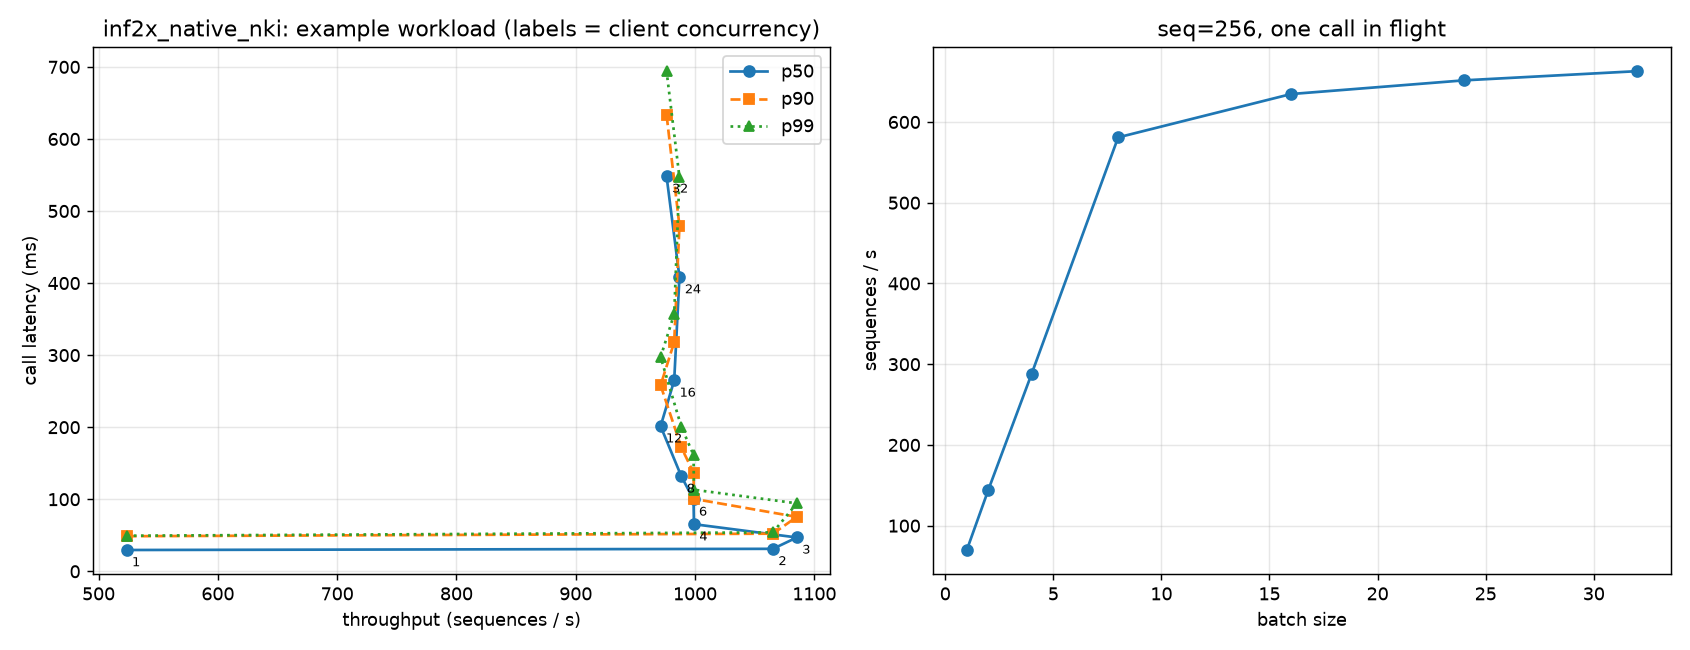

('triton-prodmix', '', 0)

In [8]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
res = {"tag": TAG, "platform": PLATFORM, "path": PATH, "nki": NKI, "lnc": LNC, "instances": NUM_INSTANCES,
       "example_mix": {str(L): {"pct_calls": v[0], "mean_seq_per_call": v[1]} for L, v in EXAMPLE_MIX.items()},
       "target_seq_pct": {str(L): round(v, 2) for L, v in TARGET_SEQ_PCT.items()},
       "buckets": BUCKETS, "curve": CURVE, "bs_sweep_256": BS_SWEEP,
       "accuracy": acc}
os.makedirs(f"{HOME}/prodmix_results", exist_ok=True)
json.dump(res, open(f"{HOME}/prodmix_results/{TAG}.json", "w"), indent=2)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
x = [r["seq_per_s"] for r in CURVE]
for key, lbl, st in [("p50_ms", "p50", "-o"), ("p90_ms", "p90", "--s"), ("p99_ms", "p99", ":^")]:
    ax[0].plot(x, [r[key] for r in CURVE], st, label=lbl)
for r in CURVE:
    ax[0].annotate(str(r["concurrency"]), (r["seq_per_s"], r["p50_ms"]), fontsize=7,
                   xytext=(3, -9), textcoords="offset points")
ax[0].set_xlabel("throughput (sequences / s)"); ax[0].set_ylabel("call latency (ms)")
ax[0].set_title(f"{TAG}: example workload (labels = client concurrency)"); ax[0].grid(alpha=.3); ax[0].legend()
ax[1].plot([r["batch"] for r in BS_SWEEP], [r["seq_per_s"] for r in BS_SWEEP], "-o")
ax[1].set_xlabel("batch size"); ax[1].set_ylabel("sequences / s"); ax[1].grid(alpha=.3)
ax[1].set_title("seq=256, one call in flight")
plt.tight_layout()
png = f"{HOME}/prodmix_results/{TAG}.png"
plt.savefig(png, dpi=130)
print("wrote", png)
from IPython.display import Image, display
display(Image(png))
sh(["sudo", "docker", "rm", "-f", CONTAINER])